In [1]:
# === Ô GHI LOG ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "00_EDA_tong_hop_C1_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-15 21:06:16 | INFO | Bắt đầu chạy 00_EDA_tong_hop_C1_Han – người chạy: Han – file log: C:\Users\ACER\Documents\GitHub\Challenge_1_House_Prices\logs\eda_log\2026-11-15_2106_00_EDA_tong_hop_C1_Han.log


# EDA tổng hợp E0.1 → E0.4 (C1 – House Prices)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 13/11/2026 – sinh tự động bằng `notebooks/eda/gop_eda.py` từ 4 notebook con |
| **Câu hỏi nghiên cứu** | RQ0: Những đặc trưng nào quyết định giá nhà, và cần bao nhiêu đặc trưng là đủ? |
| **Đọc vào** | `data/raw/train.csv`, `test.csv`, `data_description.txt` |
| **Ghi ra** | `figures/eda/c1_E0.1_*` … `c1_E0.4_*` (giống 4 notebook con), `c1_E0_tong_hop_tom_tat.txt` |

Đây là **bản chính thức đọc từ trên xuống dưới** của toàn bộ phần EDA. Nội dung từng phần được chép
nguyên từ notebook con, chỉ bỏ các ô chuẩn bị bị lặp lại:

| Phần | Notebook con (nguồn gốc) |
|---|---|
| E0.1 | `01_E0.1_thong_ke_mo_ta_Han.ipynb` |
| E0.2 | `01_E0.2_xep_hang_dac_trung_Han.ipynb` |
| E0.3 | `01_E0.3_ngoai_lai_da_cong_tuyen_Han.ipynb` |
| E0.4 | `01_E0.4_so_dac_trung_toi_uu_Han.ipynb` |

**Sửa code:** sửa trong notebook con, rồi chạy `python notebooks/eda/gop_eda.py` để sinh lại file này.
**Cách chạy:** Run All. File log nằm ở `logs/eda_log/`. W&B tắt (các run E0.1–E0.4 đã log ở notebook con).

---
# Phần E0.1
> Nguồn: `notebooks/eda/01_E0.1_thong_ke_mo_ta_Han.ipynb`

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", font_scale=1.0)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda/
DATA = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# W&B: USE_WANDB là công tắc chung; LOG chọn thí nghiệm nào được log ở lần chạy này.
# Thí nghiệm đã log rồi thì để False để không tạo run trùng.
# Các run W&B của E0.1–E0.4 đã log ngày 07–08/11 (xem evidence/c1_wandb_Han_10-11.png).
# Để USE_WANDB = False khi chạy lại để không tạo run trùng; bật True nếu cần log run mới.
USE_WANDB = False
LOG = {}
WANDB_ENTITY = "sgu-mayhoc-nhom11"
WANDB_PROJECT = "challenge-1-house-prices"
log.info(f"ROOT: {ROOT}")

2026-11-15 21:06:18 | INFO | ROOT: C:\Users\ACER\Documents\GitHub\Challenge_1_House_Prices


In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
TARGET = "SalePrice"
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (1460, 81) | test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## E0.1 – Dữ liệu trông thế nào?

Số mẫu, kiểu cột, tỉ lệ thiếu, phân phối biến mục tiêu.

In [4]:
X = train.drop(columns=["Id", TARGET])
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

overview = pd.DataFrame({
    "Chỉ số": ["Số mẫu train", "Số mẫu test", "Số đặc trưng", "Đặc trưng số", "Đặc trưng phân loại",
               "Cột có giá trị thiếu (train)", "Tỉ lệ ô thiếu (train)"],
    "Giá trị": [len(train), len(test), X.shape[1], len(num_cols), len(cat_cols),
                int((X.isna().sum() > 0).sum()), f"{X.isna().mean().mean():.2%}"],
})
overview.to_csv(FIG / "c1_E0.1_tong_quan.csv", index=False)
overview

,Chỉ số,Giá trị
0,Số mẫu train,1460
1,Số mẫu test,1459
2,Số đặc trưng,79
3,Đặc trưng số,36
4,Đặc trưng phân loại,43
5,Cột có giá trị thiếu (train),19
6,Tỉ lệ ô thiếu (train),6.79%


In [5]:
# Bảng mô tả từng cột: mô tả gốc lấy từ data/raw/data_description.txt (Kaggle), kiểu, số giá trị khác nhau, tỉ lệ thiếu
import re
mo_ta = {}
for line in (DATA / "data_description.txt").read_text(encoding="utf-8", errors="ignore").splitlines():
    m = re.match(r"^([A-Za-z0-9]+):\s*(.*)$", line)
    if m:
        mo_ta[m.group(1)] = m.group(2).strip()
ten_khac = {"BedroomAbvGr": "Bedroom", "KitchenAbvGr": "Kitchen"}  # tên cột khác tên trong file mô tả
bang_cot = pd.DataFrame({
    "kieu": ["số" if c in num_cols else "phân loại" for c in X.columns],
    "so_gia_tri_khac_nhau": [X[c].nunique() for c in X.columns],
    "ti_le_thieu": [X[c].isna().mean() for c in X.columns],
    "mo_ta_goc (data_description.txt)": [mo_ta.get(c, mo_ta.get(ten_khac.get(c, ""), "(không có trong file mô tả)")) for c in X.columns],
}, index=pd.Index(X.columns, name="cot"))
bang_cot.to_csv(FIG / "c1_E0.1_mo_ta_cot.csv")
log.info(f"Bảng mô tả cột: {len(bang_cot)} cột, {int((bang_cot.iloc[:, 3] == '(không có trong file mô tả)').sum())} cột không tìm thấy mô tả")
bang_cot.style.format({"ti_le_thieu": "{:.1%}"})

2026-11-15 21:06:18 | INFO | Bảng mô tả cột: 79 cột, 0 cột không tìm thấy mô tả


,kieu,so_gia_tri_khac_nhau,ti_le_thieu,mo_ta_goc (data_description.txt)
cot,,,,
MSSubClass,số,15,0.0%,Identifies the type of dwelling involved in the sale.
MSZoning,phân loại,5,0.0%,Identifies the general zoning classification of the sale.
LotFrontage,số,110,17.7%,Linear feet of street connected to property
LotArea,số,1073,0.0%,Lot size in square feet
Street,phân loại,2,0.0%,Type of road access to property
Alley,phân loại,2,93.8%,Type of alley access to property
LotShape,phân loại,4,0.0%,General shape of property
LandContour,phân loại,4,0.0%,Flatness of the property
Utilities,phân loại,2,0.0%,Type of utilities available


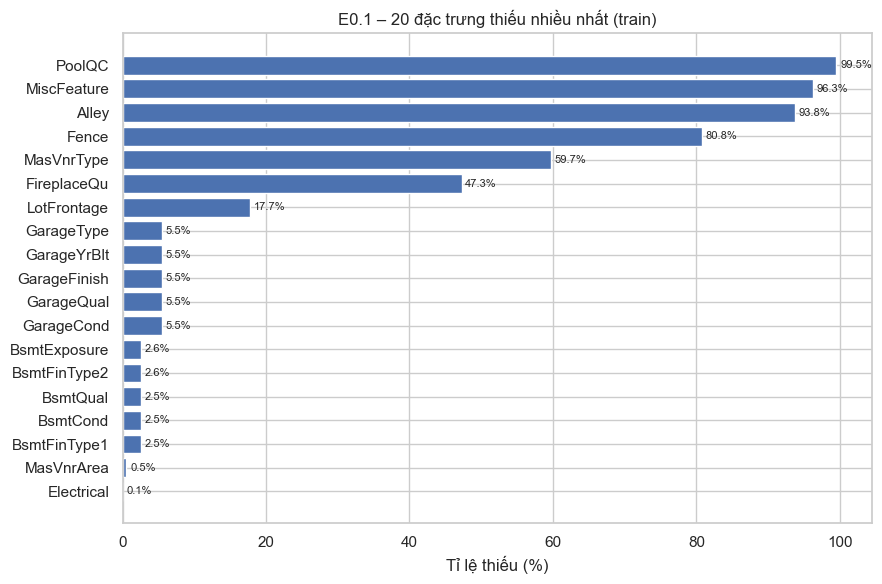

,so_thieu,ti_le,kieu
PoolQC,1453,0.995205,phân loại
MiscFeature,1406,0.963014,phân loại
Alley,1369,0.937671,phân loại
Fence,1179,0.807534,phân loại
MasVnrType,872,0.597260,phân loại
FireplaceQu,690,0.472603,phân loại
LotFrontage,259,0.177397,số
GarageType,81,0.055479,phân loại
GarageYrBlt,81,0.055479,số
GarageFinish,81,0.055479,phân loại


In [6]:
miss = (pd.DataFrame({"so_thieu": X.isna().sum(), "ti_le": X.isna().mean()})
          .query("so_thieu > 0").sort_values("ti_le", ascending=False))
miss["kieu"] = ["số" if c in num_cols else "phân loại" for c in miss.index]
miss.to_csv(FIG / "c1_E0.1_ti_le_thieu.csv")

top = miss.head(20)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index[::-1], top["ti_le"][::-1] * 100, color="#4C72B0")
ax.set_xlabel("Tỉ lệ thiếu (%)")
ax.set_title("E0.1 – 20 đặc trưng thiếu nhiều nhất (train)")
for i, v in enumerate(top["ti_le"][::-1] * 100):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "c1_E0.1_ti_le_thieu.png", dpi=150); plt.show()
miss.head(20)

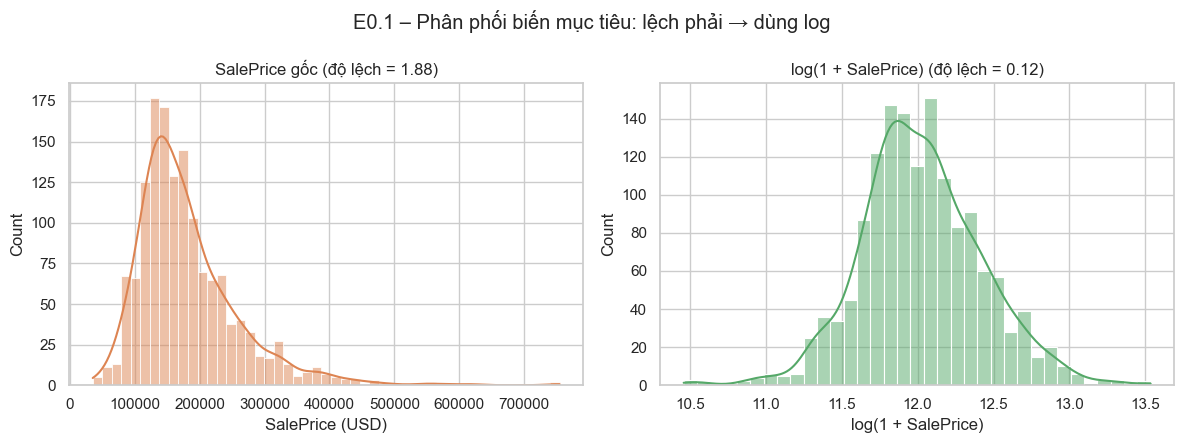

count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64

In [7]:
y = train[TARGET]
y_log = np.log1p(y)
skew_raw, skew_log = stats.skew(y), stats.skew(y_log)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(y, kde=True, ax=axes[0], color="#DD8452")
axes[0].set_title(f"SalePrice gốc (độ lệch = {skew_raw:.2f})"); axes[0].set_xlabel("SalePrice (USD)")
sns.histplot(y_log, kde=True, ax=axes[1], color="#55A868")
axes[1].set_title(f"log(1 + SalePrice) (độ lệch = {skew_log:.2f})"); axes[1].set_xlabel("log(1 + SalePrice)")
fig.suptitle("E0.1 – Phân phối biến mục tiêu: lệch phải → dùng log")
plt.tight_layout(); plt.savefig(FIG / "c1_E0.1_phan_phoi_SalePrice.png", dpi=150); plt.show()
y.describe().round(0)

In [8]:
skew_feat = X[num_cols].apply(lambda s: stats.skew(s.dropna())).sort_values(ascending=False)
skew_tbl = skew_feat.to_frame("do_lech")
skew_tbl.to_csv(FIG / "c1_E0.1_do_lech_dac_trung_so.csv")
print("Số đặc trưng số lệch mạnh (|skew| > 1):", int((skew_feat.abs() > 1).sum()))
skew_tbl.head(10).round(2)

Số đặc trưng số lệch mạnh (|skew| > 1): 19


,do_lech
MiscVal,24.45
PoolArea,14.81
LotArea,12.20
3SsnPorch,10.29
LowQualFinSF,9.00
KitchenAbvGr,4.48
BsmtFinSF2,4.25
ScreenPorch,4.12
BsmtHalfBath,4.10
EnclosedPorch,3.09


2026-11-15 21:06:20 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-15 21:06:20 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


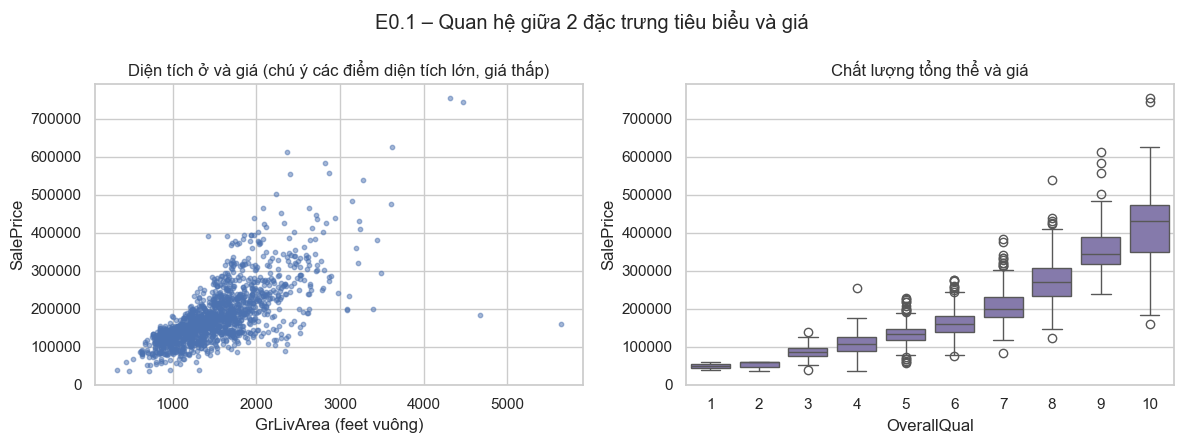

In [9]:
# Hai đặc trưng thường liên quan giá nhất: diện tích ở và chất lượng tổng thể
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(train["GrLivArea"], y, s=10, alpha=0.5)
axes[0].set_xlabel("GrLivArea (feet vuông)"); axes[0].set_ylabel("SalePrice")
axes[0].set_title("Diện tích ở và giá (chú ý các điểm diện tích lớn, giá thấp)")
sns.boxplot(x=train["OverallQual"], y=y, ax=axes[1], color="#8172B3")
axes[1].set_title("Chất lượng tổng thể và giá")
fig.suptitle("E0.1 – Quan hệ giữa 2 đặc trưng tiêu biểu và giá")
plt.tight_layout(); plt.savefig(FIG / "c1_E0.1_GrLivArea_OverallQual.png", dpi=150); plt.show()

## Tóm tắt E0.1

In [10]:
summary = f"""E0.1 (C1): {len(train)} mẫu train, {len(test)} mẫu test, {X.shape[1]} đặc trưng ({len(num_cols)} số, {len(cat_cols)} phân loại).
  {len(miss)} cột có giá trị thiếu; thiếu nhiều nhất: {', '.join(f'{c} ({p:.0%})' for c, p in miss['ti_le'].head(4).items())}.
  SalePrice lệch phải (skew = {skew_raw:.2f}); sau log còn {skew_log:.2f} → dùng log(1+SalePrice) làm mục tiêu.
  {int((skew_feat.abs() > 1).sum())} đặc trưng số lệch mạnh (|skew| > 1)."""
log.info("Tóm tắt " + "E0.1" + ":\n" + summary)
(FIG / "c1_E0.1_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-15 21:06:21 | INFO | Tóm tắt E0.1:
E0.1 (C1): 1460 mẫu train, 1459 mẫu test, 79 đặc trưng (36 số, 43 phân loại).
  19 cột có giá trị thiếu; thiếu nhiều nhất: PoolQC (100%), MiscFeature (96%), Alley (94%), Fence (81%).
  SalePrice lệch phải (skew = 1.88); sau log còn 0.12 → dùng log(1+SalePrice) làm mục tiêu.
  19 đặc trưng số lệch mạnh (|skew| > 1).


316

---
# Phần E0.2
> Nguồn: `notebooks/eda/01_E0.2_xep_hang_dac_trung_Han.ipynb`

## E0.2 – Yếu tố nào quan trọng nhất?

Bốn thước đo, tất cả so với `log(1 + SalePrice)`:

1. **Tương quan Spearman** (đặc trưng số).
2. **Mutual information** (mọi đặc trưng; đặc trưng phân loại được mã hóa số thứ tự, giá trị thiếu là một nhóm riêng).
3. **Kruskal–Wallis** (đặc trưng phân loại): giá có khác nhau giữa các nhóm không.
4. **SFS đơn biến**: R² 5-fold CV của hồi quy tuyến tính chỉ dùng một đặc trưng (đặc trưng phân loại dùng one-hot).

Mỗi thước đo cho một thứ hạng; xếp hạng cuối là **thứ hạng trung bình** trên các thước đo áp dụng được.

In [11]:
# Chuẩn bị: điền thiếu đơn giản chỉ để phân tích (không phải pipeline mô hình)
Xa = X.copy()
for c in num_cols:
    Xa[c] = Xa[c].fillna(Xa[c].median())
for c in cat_cols:
    Xa[c] = Xa[c].fillna("Missing")
X_codes = Xa.copy()
for c in cat_cols:
    X_codes[c] = X_codes[c].astype("category").cat.codes

# 1. Spearman
spear = Xa[num_cols].apply(lambda s: stats.spearmanr(s, y_log)[0]).abs()

# 2. Mutual information
disc = np.array([c in cat_cols for c in X_codes.columns])
mi = pd.Series(mutual_info_regression(X_codes, y_log, discrete_features=disc, random_state=SEED),
               index=X_codes.columns)

# 3. Kruskal–Wallis
def kruskal_h(c):
    groups = [y_log[Xa[c] == g] for g in Xa[c].unique()]
    groups = [g for g in groups if len(g) > 1]
    return stats.kruskal(*groups)[0] if len(groups) > 1 else np.nan
kw = pd.Series({c: kruskal_h(c) for c in cat_cols})

# 4. SFS đơn biến: R² 5-fold CV với hồi quy tuyến tính trên từng đặc trưng
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
def r2_single(c):
    Z = pd.get_dummies(Xa[c], drop_first=True) if c in cat_cols else Xa[[c]]
    return cross_val_score(LinearRegression(), Z, y_log, cv=kf, scoring="r2").mean()
sfs = pd.Series({c: r2_single(c) for c in X.columns})

kieu = pd.Series({c: ("số" if c in num_cols else "phân loại") for c in X.columns})
scores = pd.DataFrame({"kieu": kieu, "spearman_abs": spear, "mutual_info": mi, "kruskal_H": kw, "R2_don_bien": sfs})
ranks = scores[["spearman_abs", "mutual_info", "kruskal_H", "R2_don_bien"]].rank(ascending=False)
scores["hang_trung_binh"] = ranks.mean(axis=1, skipna=True)
scores = scores.sort_values("hang_trung_binh", kind="stable")
scores.to_csv(FIG / "c1_E0.2_xep_hang_dac_trung.csv")
scores.head(15).round(3)

,kieu,spearman_abs,mutual_info,kruskal_H,R2_don_bien,hang_trung_binh
OverallQual,số,0.810,0.566,NaN,0.661,1.000
Neighborhood,phân loại,NaN,0.528,868.532,0.549,1.667
GrLivArea,số,0.731,0.458,NaN,0.476,2.667
GarageCars,số,0.691,0.374,NaN,0.463,3.667
ExterQual,phân loại,NaN,0.332,683.440,0.452,5.000
GarageArea,số,0.649,0.363,NaN,0.422,6.000
BsmtQual,phân loại,NaN,0.323,674.411,0.447,6.333
KitchenQual,phân loại,NaN,0.330,661.482,0.445,6.667
TotalBsmtSF,số,0.603,0.361,NaN,0.350,7.667
YearBuilt,số,0.653,0.356,NaN,0.337,7.667


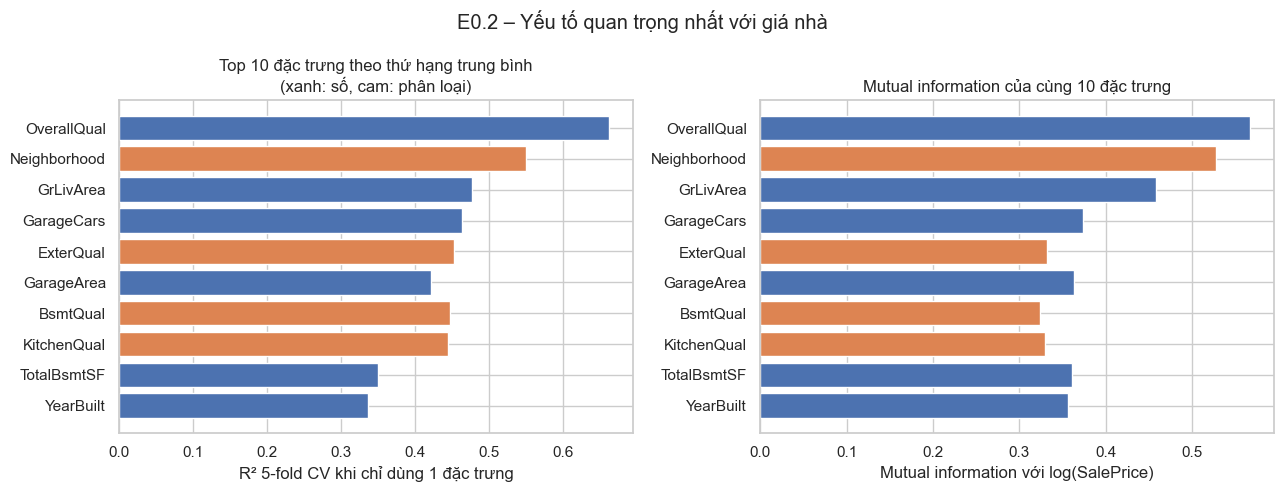

In [12]:
top10 = scores.head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ["#4C72B0" if k == "số" else "#DD8452" for k in top10["kieu"]]
axes[0].barh(top10.index[::-1], top10["R2_don_bien"][::-1], color=colors[::-1])
axes[0].set_xlabel("R² 5-fold CV khi chỉ dùng 1 đặc trưng")
axes[0].set_title("Top 10 đặc trưng theo thứ hạng trung bình\n(xanh: số, cam: phân loại)")
axes[1].barh(top10.index[::-1], top10["mutual_info"][::-1], color=colors[::-1])
axes[1].set_xlabel("Mutual information với log(SalePrice)")
axes[1].set_title("Mutual information của cùng 10 đặc trưng")
fig.suptitle("E0.2 – Yếu tố quan trọng nhất với giá nhà")
plt.tight_layout(); plt.savefig(FIG / "c1_E0.2_top10_dac_trung.png", dpi=150); plt.show()

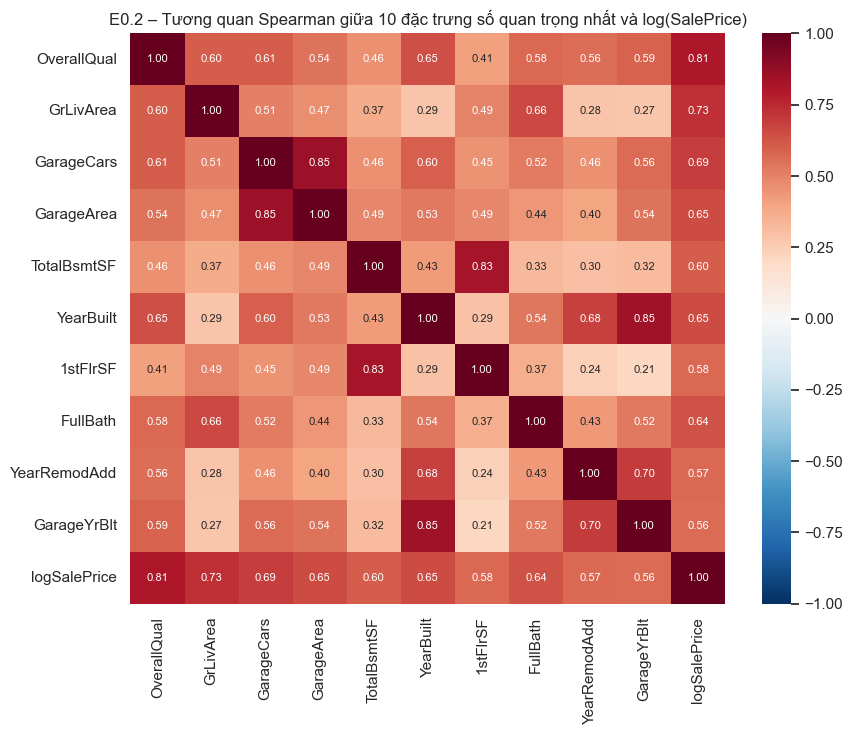

Cặp đặc trưng tương quan > 0.8 (gợi ý cho E0.3): [('GarageCars', 'GarageArea', np.float64(0.85)), ('TotalBsmtSF', '1stFlrSF', np.float64(0.83)), ('YearBuilt', 'GarageYrBlt', np.float64(0.85))]


In [13]:
top_num = [c for c in scores.index if c in num_cols][:10]
corr = pd.concat([Xa[top_num], y_log.rename("logSalePrice")], axis=1).corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
ax.set_title("E0.2 – Tương quan Spearman giữa 10 đặc trưng số quan trọng nhất và log(SalePrice)")
plt.tight_layout(); plt.savefig(FIG / "c1_E0.2_tuong_quan_top10.png", dpi=150); plt.show()

high_pairs = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(top_num) for b in top_num[i+1:]
              if abs(corr.loc[a, b]) > 0.8]
print("Cặp đặc trưng tương quan > 0.8 (gợi ý cho E0.3):", high_pairs or "không có")

## Tóm tắt E0.2

In [14]:
summary = f"""E0.2 (C1): top 10 đặc trưng theo thứ hạng trung bình của 4 thước đo:
  {', '.join(scores.index[:10])}.
  Đặc trưng đơn lẻ tốt nhất: {scores['R2_don_bien'].idxmax()} (R² CV = {scores['R2_don_bien'].max():.3f})."""
log.info("Tóm tắt " + "E0.2" + ":\n" + summary)
(FIG / "c1_E0.2_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-15 21:06:27 | INFO | Tóm tắt E0.2:
E0.2 (C1): top 10 đặc trưng theo thứ hạng trung bình của 4 thước đo:
  OverallQual, Neighborhood, GrLivArea, GarageCars, ExterQual, GarageArea, BsmtQual, KitchenQual, TotalBsmtSF, YearBuilt.
  Đặc trưng đơn lẻ tốt nhất: OverallQual (R² CV = 0.661).


248

---
# Phần E0.3
> Nguồn: `notebooks/eda/01_E0.3_ngoai_lai_da_cong_tuyen_Han.ipynb`

In [15]:
# Chuẩn bị: điền thiếu đơn giản chỉ để phân tích (không phải pipeline mô hình)
Xa = X.copy()
for c in num_cols:
    Xa[c] = Xa[c].fillna(Xa[c].median())
for c in cat_cols:
    Xa[c] = Xa[c].fillna("Missing")
X_codes = Xa.copy()
for c in cat_cols:
    X_codes[c] = X_codes[c].astype("category").cat.codes

## E0.3 – Có ngoại lai, đa cộng tuyến không?

- **Ngoại lai theo từng đặc trưng:** đếm số điểm nằm ngoài khoảng [Q1 − 3·IQR, Q3 + 3·IQR] (ngoại lai cực đoan).
- **Ngoại lai theo giá:** hồi quy tuyến tính log(SalePrice) trên 10 đặc trưng số quan trọng nhất (E0.2); điểm có phần dư chuẩn hóa |z| > 3 là căn có giá bất thường so với đặc điểm của nó.
- **Đa cộng tuyến:** cặp đặc trưng số có |tương quan Pearson| > 0.8 và hệ số VIF (VIF > 10 là đa cộng tuyến mạnh, VIF = ∞ là phụ thuộc tuyến tính hoàn toàn).

In [16]:
# Ngoại lai cực đoan theo IQR cho từng đặc trưng số
q1, q3 = Xa[num_cols].quantile(0.25), Xa[num_cols].quantile(0.75)
iqr = q3 - q1
extreme = ((Xa[num_cols] < q1 - 3 * iqr) | (Xa[num_cols] > q3 + 3 * iqr)) & (iqr > 0)
iqr_tbl = extreme.sum().sort_values(ascending=False).to_frame("so_diem_ngoai_lai")
iqr_tbl["ti_le"] = iqr_tbl["so_diem_ngoai_lai"] / len(Xa)
iqr_tbl = iqr_tbl.query("so_diem_ngoai_lai > 0")
iqr_tbl.to_csv(FIG / "c1_E0.3_ngoai_lai_IQR.csv")
print("Số đặc trưng số có ngoại lai cực đoan:", len(iqr_tbl))
iqr_tbl.head(10).style.format({"ti_le": "{:.1%}"})

Số đặc trưng số có ngoại lai cực đoan: 13

,so_diem_ngoai_lai,ti_le
LotArea,34,2.3%
MasVnrArea,28,1.9%
OpenPorchSF,18,1.2%
LotFrontage,16,1.1%
TotalBsmtSF,5,0.3%
GrLivArea,4,0.3%
GarageArea,3,0.2%
WoodDeckSF,3,0.2%
1stFlrSF,3,0.2%
OverallCond,1,0.1%


Căn diện tích > 4000 nhưng giá < 300k (Id): [524, 1299]
Số căn có |z phần dư| > 3: 13


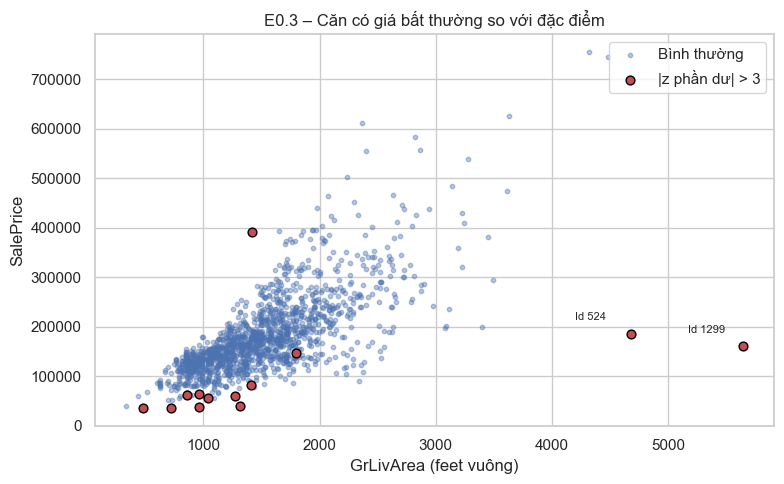

,Id,GrLivArea,OverallQual,SalePrice,z_phan_du
1298,1299,5642,10,160000,-13.09
523,524,4676,10,184750,-8.91
30,31,1317,4,40000,-5.47
632,633,1411,7,82500,-4.88
410,411,1276,5,60000,-4.51
812,813,1044,5,55993,-4.49
495,496,720,4,34900,-4.48
1324,1325,1795,8,147000,-4.09
916,917,480,2,35311,-3.99
462,463,864,5,62383,-3.53


In [17]:
# Ngoại lai theo giá: phần dư của hồi quy tuyến tính trên 10 đặc trưng số quan trọng nhất
top_num10 = [c for c in scores.index if c in num_cols][:10]
lr = LinearRegression().fit(Xa[top_num10], y_log)
resid = y_log - lr.predict(Xa[top_num10])
z = (resid - resid.mean()) / resid.std()
out_idx = z[z.abs() > 3].index
outliers = train.loc[out_idx, ["Id", "GrLivArea", "OverallQual", "SalePrice"]].assign(z_phan_du=z[out_idx].round(2))
outliers = outliers.sort_values("z_phan_du")
outliers.to_csv(FIG / "c1_E0.3_ngoai_lai_theo_gia.csv", index=False)

big_cheap = train[(train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)]["Id"].tolist()
print("Căn diện tích > 4000 nhưng giá < 300k (Id):", big_cheap)
print("Số căn có |z phần dư| > 3:", len(outliers))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(train["GrLivArea"], y, s=10, alpha=0.4, label="Bình thường")
ax.scatter(train.loc[out_idx, "GrLivArea"], y[out_idx], s=40, color="#C44E52",
           edgecolor="black", label="|z phần dư| > 3")
for i in train.index[train["Id"].isin(big_cheap)]:
    ax.annotate(f"Id {train.at[i, 'Id']}", (train.at[i, "GrLivArea"], y[i]),
                textcoords="offset points", xytext=(-40, 10), fontsize=8)
ax.set_xlabel("GrLivArea (feet vuông)"); ax.set_ylabel("SalePrice")
ax.set_title("E0.3 – Căn có giá bất thường so với đặc điểm")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "c1_E0.3_ngoai_lai_theo_gia.png", dpi=150); plt.show()
outliers

Cặp |tương quan| > 0.8:
dac_trung_1  dac_trung_2  tuong_quan
 GarageCars   GarageArea        0.88
  GrLivArea TotRmsAbvGrd        0.83
TotalBsmtSF     1stFlrSF        0.82

Đặc trưng VIF = ∞ (là tổng của các cột khác): ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'GrLivArea', 'LowQualFinSF', '2ndFlrSF', '1stFlrSF']
Đặc trưng VIF > 10: []


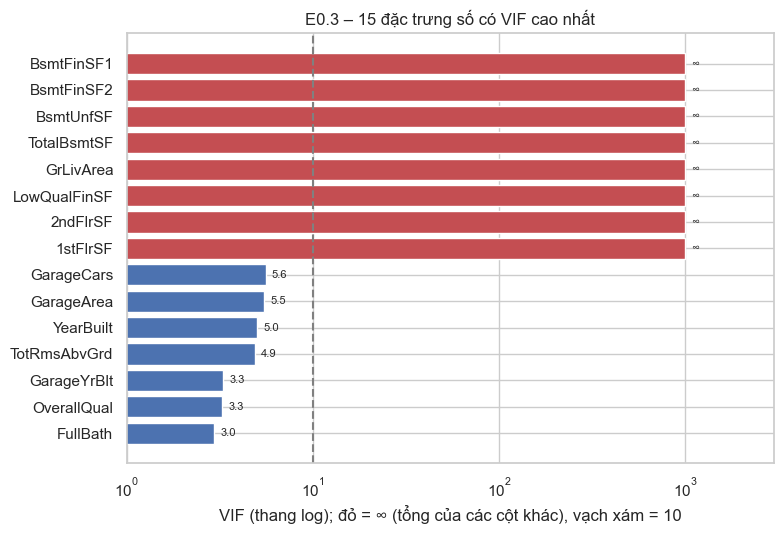

In [18]:
# Đa cộng tuyến: cặp tương quan cao và VIF
pear = Xa[num_cols].corr()
pairs = (pear.where(np.triu(np.ones(pear.shape, dtype=bool), k=1)).stack()
             .rename("tuong_quan").reset_index().rename(columns={"level_0": "dac_trung_1", "level_1": "dac_trung_2"}))
high_corr = pairs[pairs["tuong_quan"].abs() > 0.8].sort_values("tuong_quan", key=abs, ascending=False)
high_corr.to_csv(FIG / "c1_E0.3_cap_tuong_quan_cao.csv", index=False)

def vif_table(df):
    vals = {}
    for c in df.columns:
        others = df.drop(columns=c)
        r2 = LinearRegression().fit(others, df[c]).score(others, df[c])
        vals[c] = np.inf if r2 > 0.9999 else 1 / (1 - r2)
    return pd.Series(vals).sort_values(ascending=False)

num_vif = [c for c in num_cols if Xa[c].std() > 0]
vif = vif_table(Xa[num_vif]).to_frame("VIF")
vif.to_csv(FIG / "c1_E0.3_vif.csv")
print("Cặp |tương quan| > 0.8:"); print(high_corr.round(2).to_string(index=False))
print("\nĐặc trưng VIF = ∞ (là tổng của các cột khác):", vif.index[np.isinf(vif["VIF"])].tolist())
print("Đặc trưng VIF > 10:", vif.index[(vif["VIF"] > 10) & ~np.isinf(vif["VIF"])].tolist())

plot_vif = vif.head(15)["VIF"]
INF_BAR = 1000  # vẽ VIF = ∞ thành thanh dài 1000 và ghi chú "∞"
bars = plot_vif.replace(np.inf, INF_BAR)
colors = ["#C44E52" if np.isinf(v) else ("#DD8452" if v > 10 else "#4C72B0") for v in plot_vif]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(plot_vif.index[::-1], bars[::-1], color=colors[::-1])
for i, v in enumerate(plot_vif[::-1]):
    ax.text(min(v, INF_BAR) * 1.08, i, "∞" if np.isinf(v) else f"{v:.1f}", va="center", fontsize=8)
ax.axvline(10, ls="--", color="gray"); ax.set_xscale("log"); ax.set_xlim(1, INF_BAR * 3)
ax.set_xlabel("VIF (thang log); đỏ = ∞ (tổng của các cột khác), vạch xám = 10")
ax.set_title("E0.3 – 15 đặc trưng số có VIF cao nhất")
plt.tight_layout(); plt.savefig(FIG / "c1_E0.3_vif.png", dpi=150); plt.show()

## Tóm tắt E0.3

In [19]:
summary = f"""E0.3 (C1): {len(iqr_tbl)} đặc trưng số có ngoại lai cực đoan (ngoài 3·IQR); {len(outliers)} căn có giá bất thường (|z phần dư| > 3).
  Căn diện tích > 4000 nhưng giá < 300k: Id {big_cheap} → đề xuất bỏ khi huấn luyện.
  {len(high_corr)} cặp tương quan > 0.8: {'; '.join(f'{a}–{b} ({r:.2f})' for a, b, r in high_corr.head(5).itertuples(index=False))}.
  VIF = ∞ (là tổng các cột khác): {', '.join(vif.index[np.isinf(vif['VIF'])])}."""
log.info("Tóm tắt " + "E0.3" + ":\n" + summary)
(FIG / "c1_E0.3_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-15 21:06:30 | INFO | Tóm tắt E0.3:
E0.3 (C1): 13 đặc trưng số có ngoại lai cực đoan (ngoài 3·IQR); 13 căn có giá bất thường (|z phần dư| > 3).
  Căn diện tích > 4000 nhưng giá < 300k: Id [524, 1299] → đề xuất bỏ khi huấn luyện.
  3 cặp tương quan > 0.8: GarageCars–GarageArea (0.88); GrLivArea–TotRmsAbvGrd (0.83); TotalBsmtSF–1stFlrSF (0.82).
  VIF = ∞ (là tổng các cột khác): BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, GrLivArea, LowQualFinSF, 2ndFlrSF, 1stFlrSF.


435

---
# Phần E0.4
> Nguồn: `notebooks/eda/01_E0.4_so_dac_trung_toi_uu_Han.ipynb`

## E0.4 – Bao nhiêu đặc trưng là đủ?

Chọn đặc trưng tuần tự tiến (forward SFS): bắt đầu từ tập rỗng, mỗi bước thêm đặc trưng làm R² 5-fold CV tăng nhiều nhất. Mô hình đơn giản: Ridge (α = 1) trên log(SalePrice); đặc trưng số được chuẩn hóa, đặc trưng phân loại được one-hot (mỗi đặc trưng phân loại tính là **một** đặc trưng). Bỏ 2 ngoại lai diện tích lớn giá thấp tìm được ở E0.3.

So sánh thêm đường "lấy top-k theo xếp hạng E0.2" để xem xếp hạng đơn biến có đủ tốt không. **Sweet spot** là số đặc trưng nhỏ nhất đạt R² cách mức cao nhất không quá 0.005.

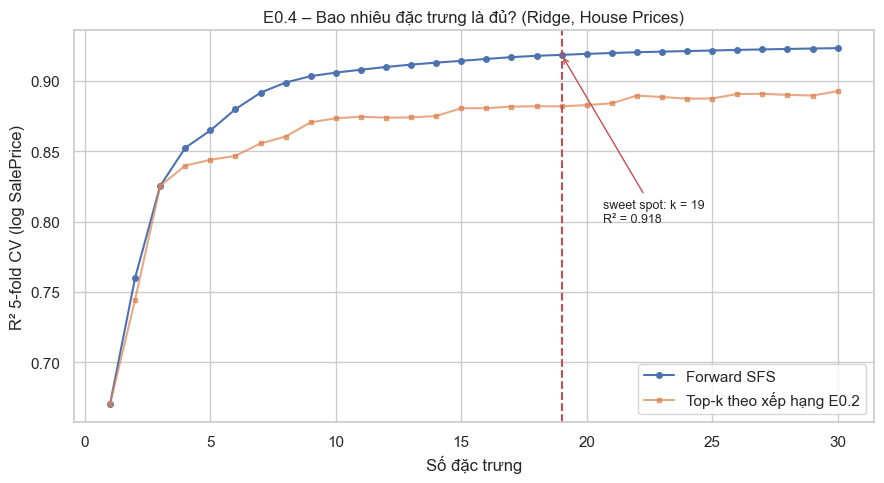

Sweet spot: 19 đặc trưng, R² = 0.918 (cao nhất 0.923 ở k = 30)
Thứ tự SFS chọn: OverallQual, GrLivArea, Neighborhood, BsmtFinSF1, OverallCond, YearBuilt, TotalBsmtSF, GarageCars, BldgType, MSZoning, SaleCondition, LotArea, CentralAir, KitchenQual, Functional, BsmtExposure, Condition1, ScreenPorch, Fireplaces


In [20]:
from sklearn.linear_model import Ridge
K_MAX = 30
keep = ~train["Id"].isin(big_cheap)
Xs, ys = Xa[keep].reset_index(drop=True), y_log[keep].reset_index(drop=True)

# Mỗi đặc trưng gốc → một khối cột (số: chuẩn hóa; phân loại: one-hot)
blocks = {}
for c in X.columns:
    if c in num_cols:
        v = Xs[c].astype(float)
        blocks[c] = ((v - v.mean()) / (v.std() if v.std() > 0 else 1)).to_numpy()[:, None]
    else:
        blocks[c] = pd.get_dummies(Xs[c], drop_first=True).to_numpy(dtype=float)
kf4 = KFold(n_splits=5, shuffle=True, random_state=SEED)
def cv_r2(feats):
    M = np.hstack([blocks[f] for f in feats])
    return cross_val_score(Ridge(alpha=1.0), M, ys, cv=kf4, scoring="r2").mean()

selected, sfs_curve = [], []
remaining = list(X.columns)
for k in range(1, K_MAX + 1):
    best = max(remaining, key=lambda f: cv_r2(selected + [f]))
    selected.append(best); remaining.remove(best)
    sfs_curve.append(cv_r2(selected))
rank_order = list(scores.index)
rank_curve = [cv_r2(rank_order[:k]) for k in range(1, K_MAX + 1)]

curve = pd.DataFrame({"k": range(1, K_MAX + 1), "dac_trung_them_vao": selected,
                      "R2_SFS": sfs_curve, "R2_top_k_E0.2": rank_curve})
best_r2 = curve["R2_SFS"].max()
sweet_k = int(curve.loc[curve["R2_SFS"] >= best_r2 - 0.005, "k"].min())
curve.to_csv(FIG / "c1_E0.4_duong_cong_so_dac_trung.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(curve["k"], curve["R2_SFS"], marker="o", ms=4, label="Forward SFS")
ax.plot(curve["k"], curve["R2_top_k_E0.2"], marker="s", ms=3, alpha=0.7, label="Top-k theo xếp hạng E0.2")
ax.axvline(sweet_k, ls="--", color="#C44E52")
ax.annotate(f"sweet spot: k = {sweet_k}\nR² = {curve.at[sweet_k-1, 'R2_SFS']:.3f}",
            (sweet_k, curve.at[sweet_k-1, "R2_SFS"]), textcoords="offset points", xytext=(30, -120), fontsize=9,
            arrowprops=dict(arrowstyle="->", color="#C44E52"))
ax.set_xlabel("Số đặc trưng"); ax.set_ylabel("R² 5-fold CV (log SalePrice)")
ax.set_title("E0.4 – Bao nhiêu đặc trưng là đủ? (Ridge, House Prices)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "c1_E0.4_sweet_spot.png", dpi=150); plt.show()
print(f"Sweet spot: {sweet_k} đặc trưng, R² = {curve.at[sweet_k-1, 'R2_SFS']:.3f} (cao nhất {best_r2:.3f} ở k = {int(curve.loc[curve['R2_SFS'].idxmax(), 'k'])})")
print("Thứ tự SFS chọn:", ", ".join(selected[:sweet_k]))

## Tóm tắt E0.4

In [21]:
summary = f"""E0.4 (C1): sweet spot {sweet_k} đặc trưng, R² CV = {curve.at[sweet_k-1, 'R2_SFS']:.3f} (cao nhất {best_r2:.3f}); top-{sweet_k} theo E0.2 chỉ đạt {curve.at[sweet_k-1, 'R2_top_k_E0.2']:.3f}.
  SFS chọn: {', '.join(selected[:sweet_k])}."""
log.info("Tóm tắt " + "E0.4" + ":\n" + summary)
(FIG / "c1_E0.4_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-15 21:06:59 | INFO | Tóm tắt E0.4:
E0.4 (C1): sweet spot 19 đặc trưng, R² CV = 0.918 (cao nhất 0.923); top-19 theo E0.2 chỉ đạt 0.882.
  SFS chọn: OverallQual, GrLivArea, Neighborhood, BsmtFinSF1, OverallCond, YearBuilt, TotalBsmtSF, GarageCars, BldgType, MSZoning, SaleCondition, LotArea, CentralAir, KitchenQual, Functional, BsmtExposure, Condition1, ScreenPorch, Fireplaces.


342

---
# Tóm tắt toàn bộ EDA

In [22]:
tom_tat = "\n\n".join((FIG / f"c1_{ma}_tom_tat.txt").read_text(encoding="utf-8")
                      for ma in ["E0.1", "E0.2", "E0.3", "E0.4"])
(FIG / "c1_E0_tong_hop_tom_tat.txt").write_text(tom_tat, encoding="utf-8")
log.info("Tóm tắt EDA tổng hợp:\n" + tom_tat)

2026-11-15 21:06:59 | INFO | Tóm tắt EDA tổng hợp:
E0.1 (C1): 1460 mẫu train, 1459 mẫu test, 79 đặc trưng (36 số, 43 phân loại).
  19 cột có giá trị thiếu; thiếu nhiều nhất: PoolQC (100%), MiscFeature (96%), Alley (94%), Fence (81%).
  SalePrice lệch phải (skew = 1.88); sau log còn 0.12 → dùng log(1+SalePrice) làm mục tiêu.
  19 đặc trưng số lệch mạnh (|skew| > 1).

E0.2 (C1): top 10 đặc trưng theo thứ hạng trung bình của 4 thước đo:
  OverallQual, Neighborhood, GrLivArea, GarageCars, ExterQual, GarageArea, BsmtQual, KitchenQual, TotalBsmtSF, YearBuilt.
  Đặc trưng đơn lẻ tốt nhất: OverallQual (R² CV = 0.661).

E0.3 (C1): 13 đặc trưng số có ngoại lai cực đoan (ngoài 3·IQR); 13 căn có giá bất thường (|z phần dư| > 3).
  Căn diện tích > 4000 nhưng giá < 300k: Id [524, 1299] → đề xuất bỏ khi huấn luyện.
  3 cặp tương quan > 0.8: GarageCars–GarageArea (0.88); GrLivArea–TotRmsAbvGrd (0.83); TotalBsmtSF–1stFlrSF (0.82).
  VIF = ∞ (là tổng các cột khác): BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, Tot

## Nhật ký

- 13/11/2026 – Gộp 4 notebook con gồm `01_E0.1_thong_ke_mo_ta_Han`, `01_E0.2_xep_hang_dac_trung_Han`, `01_E0.3_ngoai_lai_da_cong_tuyen_Han`, `01_E0.4_so_dac_trung_toi_uu_Han` lại thành bản hoàn chỉnh tên `00_EDA_tong_hop_C1_Han.ipynb` bằng script `gop_eda.py`. Commit `4788a81`.

## Nhận xét kiểm tra chéo – Nhung, 15/11/2026

**Chạy được không:** Có. Kéo main về nhánh Nhung, tải dữ liệu Kaggle (train.csv, test.csv, data_description.txt, sample_submission.csv) vào `data/raw/`, rồi chạy lại toàn bộ notebook (Restart + Run All bằng `jupyter nbconvert --execute`) lúc 21:06–21:07 trên Windows, Python 3.12.10. Cả 22/22 ô code chạy, số thứ tự 1→22, không có lỗi. Log: `logs/eda_log/2026-11-15_2106_00_EDA_tong_hop_C1_Han.log`. Dòng đầu log ghi "người chạy: Han" vì giữ nguyên ô 1 của Hân.

**So với lần chạy của Hân (log `2026-11-13_1846`):** các bảng trong `figures/eda/` cho cùng giá trị, chênh lệch lớn nhất khoảng 6e-15 (sai số làm tròn của máy). Khác duy nhất là thứ tự liệt kê 8 cột VIF = ∞ và thứ tự vài dòng có giá trị bằng nhau; vẫn đúng 8 cột đó.

**Số có khớp paper không** (`report/Nhom11_C1_HousePrices_Paper.pdf`, mục 1, 2 và 4):

| Paper | Số trong paper | Output notebook | Khớp |
|---|---|---|---|
| 4.1, Bảng 1 | 1.460 / 1.459 mẫu; 79 đặc trưng (36 số, 43 phân loại); 19 cột thiếu; 6,79% ô thiếu; 19 đặc trưng lệch mạnh; độ lệch 1,88 / 0,12 | `c1_E0.1_tong_quan.csv`, tóm tắt E0.1 | Có |
| 4.2 | Trung vị 163.000, cao nhất 755.000 USD | 163000 / 755000 | Có |
| 4.3 | PoolQC, MiscFeature, Alley, Fence thiếu > 80%; LotFrontage 17,7% | 100% / 96% / 94% / 81%; 0,1774 | Có |
| 4.4, Bảng 3 | 10 đặc trưng đứng đầu với Spearman, Mutual info, R² đơn biến | `c1_E0.2_xep_hang_dac_trung.csv` | Có (cả 30 số) |
| 4.4 | OverallQual R² 0,661 (E0.2), 0,670 (E0.4) | 0,661 / 0,6702 | Có |
| 4.5 | 13 căn \|z phần dư\| > 3; Id 524, 1299; 3 cặp tương quan 0,88 / 0,83 / 0,82; 8 cột là tổng các cột khác | Tóm tắt E0.3 | Có |
| 4.6, mục 2 | 3 đặc trưng 0,825; 19 đặc trưng 0,918; cao nhất 0,923 (30 đặc trưng); top-19 theo E0.2 0,882 | `c1_E0.4_duong_cong_so_dac_trung.csv`: 0,8254 / 0,9184 / 0,9231 / 0,8818 | Có |

**Góp ý:**
1. `requirements.txt` đang rỗng; phải tự cài `seaborn` mới chạy được. Nên ghi các thư viện cần dùng.
2. Ô 1 cố định `NGUOI_CHAY = "Han"`, nên log của người chạy kiểm tra vẫn ghi tên Hân.
3. Thứ tự 8 cột VIF = ∞ trong `c1_E0.3_tom_tat.txt` khác nhau giữa máy Mac và Windows. Số không đổi, chỉ cần biết khi so file.